In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import scale
import pymc as pm
import matplotlib.pyplot as plt
import seaborn as sns

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


In [3]:
# Load the data
file_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\data\BYD&Tesla.xlsx'
data = pd.read_excel(
    file_path,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
    date_parser=lambda x: pd.to_datetime(x, format='%Y-%m-%d')
)
data = data[['比亚迪股份', '特斯拉(TESLA)']]
data.columns = ['BYD', 'TESLA']

C:\Users\19927\AppData\Local\Temp\ipykernel_40336\1826086959.py:3: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  data = pd.read_excel(


In [ ]:
# Preprocess the data
print(data.isnull().sum())  # Check for missing values
data = data.loc[~data.duplicated(keep='first')]  # Remove duplicates
prices_normed = pd.DataFrame(data.apply(scale), index=data.index, columns=['BYD', 'TESLA'])

BYD      0
TESLA    0
dtype: int64
                 BYD   TESLA
日期                          
2020-03-31  174.5080  524.00
2020-04-01  163.7359  481.56
2020-04-02  169.3374  454.47
2020-04-03  166.7521  480.01
2020-04-06  169.7683  516.24


In [8]:
# Apply rolling regression
model_randomwalk = pm.Model()
with model_randomwalk:
    sigma_alpha = pm.Exponential('sigma_alpha', 50.)
    alpha = pm.GaussianRandomWalk('alpha', sigma=sigma_alpha, shape=len(prices_normed))
    sigma_beta = pm.Exponential('sigma_beta', 50.)
    beta = pm.GaussianRandomWalk('beta', sigma=sigma_beta, shape=len(prices_normed))
    regression = alpha + beta * prices_normed['TESLA']
    sigma = pm.HalfNormal('sigma', sigma=0.1)
    likelihood = pm.Normal('y', mu=regression, sigma=sigma, observed=prices_normed['BYD'])
    trace_rw = pm.sample(tune=1, draws=200, cores=4, target_accept=0.9)

d:\MG\Python\Lib\site-packages\pymc\distributions\timeseries.py:297: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100)`.You can specify an init_dist manually to suppress this warning.
  warnings.warn(
d:\MG\Python\Lib\site-packages\pymc\distributions\timeseries.py:297: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100)`.You can specify an init_dist manually to suppress this warning.
  warnings.warn(
Initializing NUTS using jitter+adapt_diag...
ERROR (pytensor.graph.rewriting.basic): Rewrite failure due to: local_subtensor_merge
ERROR (pytensor.graph.rewriting.basic): node: Subtensor{i}(Subtensor{start:stop}.0, 0)
ERROR (pytensor.graph.rewriting.basic): TRACEBACK:
ERROR (pytensor.graph.rewriting.basic): Traceback (most recent call last):
  File "d:\MG\Python\Lib\site-packages\pytensor\graph\rewriting\basic.py", line 1922, in process_node
    replacements = node_rewriter.transform(fgraph, node)
                   ^^^^^^^^

d:\MG\Python\Lib\site-packages\rich\live.py:231: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1 tune and 200 draw iterations (4 + 800 draws total) took 57 seconds.
d:\MG\Python\Lib\site-packages\arviz\stats\diagnostics.py:595: RuntimeWarning: invalid value encountered in sqrt
  rhat_value = np.sqrt(
There were 800 divergences after tuning. Increase `target_accept` or reparameterize.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


KeyError: 'alpha'

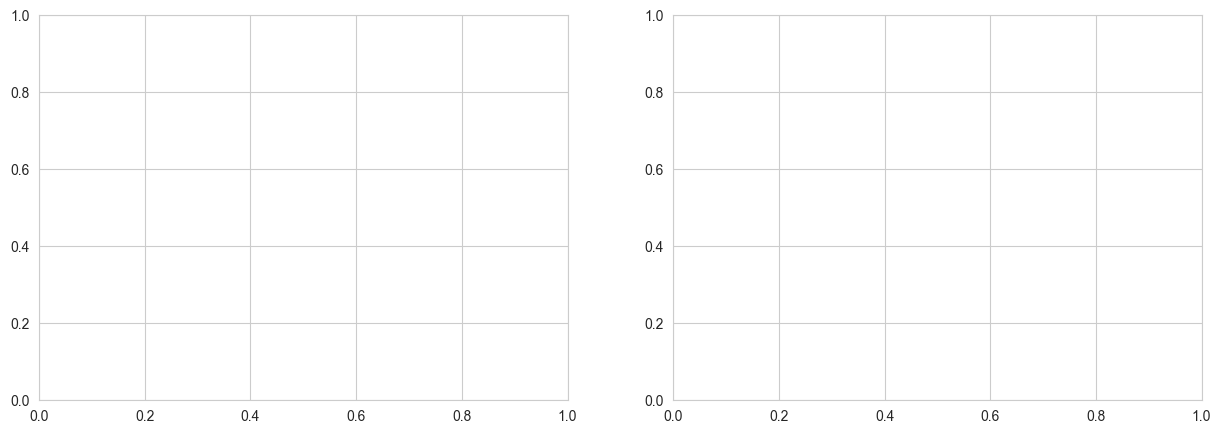

In [9]:
# Visualize results
sns.set_style('whitegrid')

# Plot coefficients
fig, axes = plt.subplots(figsize=(15, 5), ncols=2, sharex=True)
axes[0].plot(trace_rw['alpha'].T, 'r', alpha=0.05)
axes[0].set_xlabel('Time'); axes[0].set_ylabel('Alpha'); axes[0].set_title('Intercept')
axes[1].plot(trace_rw['beta'].T, 'b', alpha=0.05)
axes[1].set_xlabel('Time'); axes[1].set_ylabel('Beta'); axes[1].set_title('Slope')
date_labels = [str(p.date()) for p in prices_normed.index[::len(prices_normed)//9]]
for ax in axes:
    ax.set_xticks(range(0, len(prices_normed), len(prices_normed)//9))
    ax.set_xticklabels(date_labels, rotation=45)
fig.suptitle('Changes of Coefficients Over Time (BYD vs TESLA)', fontsize=14)
sns.despine(); fig.tight_layout(); fig.subplots_adjust(top=0.9)
plt.show()

# Plot posterior predictive lines
x = np.linspace(prices_normed['TESLA'].min(), prices_normed['TESLA'].max(), 100)
dates = [str(p.year) for p in prices_normed.index[::len(prices_normed)//9]]
colors = np.linspace(0.1, 1, len(prices_normed))
colors_sc = np.linspace(0.1, 1, len(trace_rw[::10]['alpha'].T))
cmap = plt.get_cmap('winter')
fig, ax = plt.subplots(figsize=(14, 8))
for i, (alpha, beta) in enumerate(zip(trace_rw[::25]['alpha'].T, trace_rw[::25]['beta'].T)):
    for a, b in zip(alpha[::25], beta[::25]):
        ax.plot(x, a + b * x, alpha=0.01, lw=0.5, c=cmap(colors_sc[i]))
points = ax.scatter(prices_normed['TESLA'], prices_normed['BYD'], c=colors, s=5, cmap=cmap)
cbar = plt.colorbar(points); cbar.ax.set_yticklabels(dates)
ax.set_xlabel('TESLA (Normalized Price)'); ax.set_ylabel('BYD (Normalized Price)')
ax.set_title('Posterior Predictive Regression Lines (BYD vs TESLA)')
sns.despine(); fig.tight_layout()
plt.show()